<a href="https://colab.research.google.com/github/Nkeeydata/Teus-Logistics-Analysis/blob/main/FreightAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Freight Economics and Customer Geography Analysis for Teus Logistics Company**

### **Background Story**.

**Imagine two customers browsing our storefront today. The first lives in a core hub like Lagos. She fills her cart with essentials, reaches checkout, and completes the purchase without a second thought; her freight fee is barely 10% of her order value, easily absorbed into the convenience of delivery. A thousand miles away, a second shopper in Abuja picks the exact same items. But when she hits checkout, freight surges to nearly 50% of her basket value. For her, delivery isn't a utility; it's a tax. Her hand hovers over the screen, deciding whether to abandon the cart entirely. Today, this notebook will be answering our core business question: 'Where is freight cost putting the greatest pressure on order economics?' for Teus Growth & Marketing Manager**


### **Business question:**

**Where is freight cost putting the greatest pressure on order economics?**

### *IMPORTATION OF LIBRARIES*

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 100)
DATA_DIR = Path('data')


### *DATASETS IMPORTATION AND LOADING*

In [ ]:
orders = pd.read_csv("olist_orders_dataset.csv")
order_items = pd.read_csv("olist_order_items_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")


## 1. Inspect and validate

Confirm row counts, keys, nulls and the grain of every input before joining.

## **Inspecting each dataset before joining**

In [ ]:
def audit_table(df, table_name, key_cols, grain): #defining a function named audit_table
    print(f"\n{'='*60}") # this prints the equal to sign 60 times on a new line
    print(f"TABLE: {table_name}") # prints the table name
    print(f"{'='*60}")

    # Shape
    print(f"Shape: {df.shape}")
    print(f"Rows: {df.shape[0]:,}")
    print(f"Columns: {df.shape[1]}")

    # Data types
    print("\nData Types:")
    print(df.dtypes)

    # Key information
    print(f"\nKey Columns: {key_cols}") # prints unique key in each table

    print("\nNulls in Key Columns:")
    print(df[key_cols].isnull().sum()) # print sum of null values in each unique keys

    print("\nDuplicate Keys:")
    print(df.duplicated(subset=key_cols).sum()) # prints the sum of duplicate columns in each key

    print("\nDistinct Key Count:")
    print(df[key_cols].drop_duplicates().shape[0]) # prints unique key counts after dropping the duplicates

    # Grain
    print(f"\nGrain: {grain}") # printing the grain in each table


# Orders
audit_table(
    orders,  "orders",
    ["order_id"],
    "1 row = 1 order"
)

# Order Items
audit_table(
    order_items,
    "order_items",
    ["order_id", "order_item_id"],
    "1 row = 1 item within an order"
)

# Customers
audit_table(
    customers,
    "customers",
    ["customer_id"],
    "1 row = 1 customer"
)


TABLE: orders
Shape: (12000, 8)
Rows: 12,000
Columns: 8

Data Types:
order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object

Key Columns: ['order_id']

Nulls in Key Columns:
order_id    0
dtype: int64

Duplicate Keys:
0

Distinct Key Count:
12000

Grain: 1 row = 1 order

TABLE: order_items
Shape: (13767, 7)
Rows: 13,767
Columns: 7

Data Types:
order_id                object
order_item_id            int64
product_id              object
seller_id               object
shipping_limit_date     object
price                  float64
freight_value          float64
dtype: object

Key Columns: ['order_id', 'order_item_id']

Nulls in Key Columns:
order_id         0
order_item_id    0
dtype: int64

Duplicate Keys:
0

Disti

## 2. Build the analysis table

Write the intended grain first. Then join and aggregate carefully.

## GRAIN STATEMENT

orders = 1 row per order

customers = 1 row per customer

order_items = 1 row per item within an order

How to read our data tables

Each table is built so that one row means one specific thing. Knowing this prevents counting mistakes.

Orders: one row per order. If a customer buys three products in one checkout, that is still one order.

Order Items: one row per product within an order. That same checkout creates three rows here.

Customers: one row per customer record. In this dataset, a returning shopper may appear more than once because a new record is created for each order. To count unique people, use the “unique customer ID” field.

### Freight $ Price value for each unique order

In [ ]:
order_totals = (
    order_items
    .groupby("order_id", as_index=False)
    .agg({
        "price": "sum",
        "freight_value": "sum"
    })
)
order_totals.head()

,order_id,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,58.9,13.29
1,000c3e6612759851cc3cbb4b83257986,99.0,13.71
2,000e63d38ae8c00bbcb5a30573b99628,47.9,8.88
3,0013503b13da1eac686219390b7d641b,119.9,17.32
4,001427c0ec99cf8af737bd88e92fd444,59.9,23.35


### *Above shows the `price` and `freight` value for each order*

### ORDER-LEVEL REVENUE ANALYSIS

Aggregate order_items to the order level:

In [ ]:
order_summary = (
    order_items
    .groupby("order_id", as_index=False)
    .agg(
        total_price=("price", "sum"),
        total_freight=("freight_value", "sum"),
        total_items=("order_item_id", "count")
    )
)
order_summary.head()

,order_id,total_price,total_freight,total_items
0,00010242fe8c5a6d1ba2dd792cb16214,58.9,13.29,1
1,000c3e6612759851cc3cbb4b83257986,99.0,13.71,1
2,000e63d38ae8c00bbcb5a30573b99628,47.9,8.88,1
3,0013503b13da1eac686219390b7d641b,119.9,17.32,1
4,001427c0ec99cf8af737bd88e92fd444,59.9,23.35,1


### *Above shows the `total items` for each unique order in addition to their `total price` and `total freight`*

In [ ]:
order_summary.describe()

,total_price,total_freight,total_items
count,12000.000000,12000.000000,12000.000000
mean,136.446703,22.708398,1.147250
std,206.536455,20.085134,0.534719
min,0.850000,0.000000,1.000000
25%,45.900000,13.837500,1.000000
50%,85.900000,17.210000,1.000000
75%,149.900000,24.260000,1.000000
max,5934.600000,497.080000,12.000000


## Questions to Answer from above Table

**Average order_value = 136.45**

**Largest order = 5934.6**

**Average items by customers = 1.14**

### Distribution of Order Values

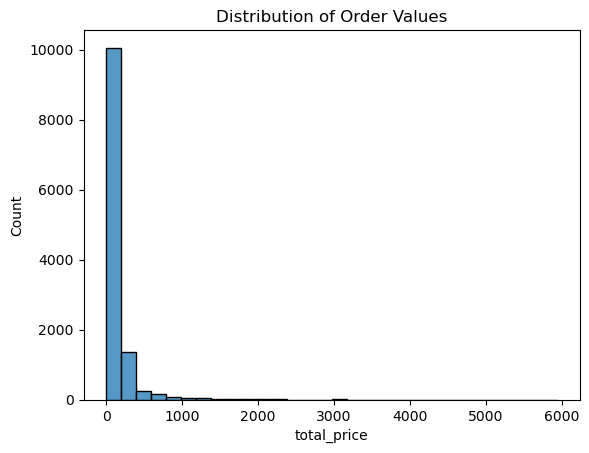

In [ ]:
sns.histplot(order_summary["total_price"], bins=30)
plt.title("Distribution of Order Values")
plt.show()

### Freight Cost Analysis

In [ ]:
order_summary["freight_pct"] = (
    order_summary["total_freight"] /
    order_summary["total_price"]
) * 100
order_summary["freight_pct"].describe() # shows the percentage of total freight per order

count    12000.000000
mean        30.804232
std         34.341763
min          0.000000
25%         13.201015
50%         22.940802
75%         38.053927
max       2144.705882
Name: freight_pct, dtype: float64

### Merging orders and order_summary into one table

In [ ]:
order_df = orders.merge(
    order_summary,
    on="order_id",
    how="left"
)



### Order Status Analysis

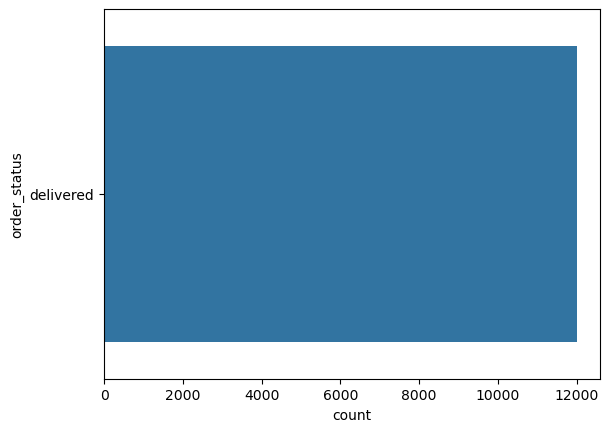

In [ ]:
order_df["order_status"].value_counts()

sns.countplot(
    y="order_status",
    data=order_df,
    order=order_df["order_status"].value_counts().index
)
plt.show()

**All the orders were delivered, and that was confirmed from our value_counts below**

In [ ]:
order_df["order_status"].value_counts()

order_status
delivered    12000
Name: count, dtype: int64

### **Number of Items per order**

In [ ]:
order_summary["total_items"].value_counts().sort_index()

total_items
1     10769
2       925
3       177
4        72
5        31
6        20
7         3
9         1
12        2
Name: count, dtype: int64

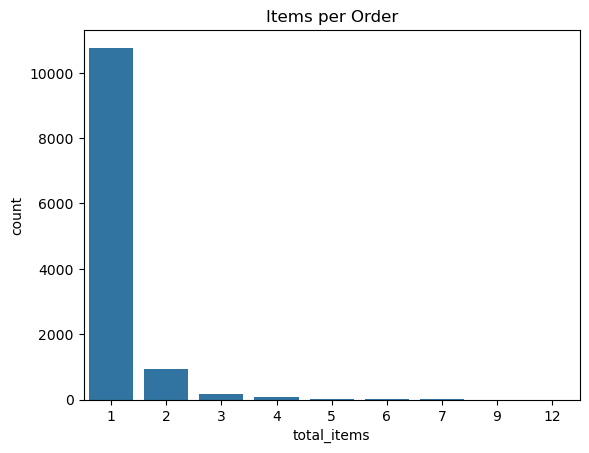

In [ ]:
# Visualizing the number of items

sns.countplot(
    x="total_items",
    data=order_summary
)
plt.title("Items per Order")
plt.show()

**What it means for the business**

Typical order = one item. Order-level metrics such as freight and revenue mostly reflect single-item purchases.

Multi-item orders are rare but important. They are few, yet each one carries more revenue and shipping weight.

Mean vs. median: the average items per order will sit slightly above 1 (pulled up by the tail), while the median is exactly 1.

Grain reminder: because most orders have only one item, order_items and orders have almost the same row count

### Revenue by Order Status

In [ ]:
order_df.groupby("order_status")["total_price"].agg(
    ["count", "sum", "mean"]
)

,count,sum,mean
order_status,,,
delivered,12000,1637360.43,136.446702


### Delivery Time Analysis

In [ ]:
date_cols = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_estimated_delivery_date"
]

for col in date_cols:
    order_df[col] = pd.to_datetime(order_df[col])

**Calcuating delivery days**

In [ ]:
order_df["delivery_days"] = (
    order_df["order_delivered_customer_date"]
    - order_df["order_purchase_timestamp"]
).dt.days

In [ ]:
order_df["delivery_days"].describe()

count    12000.000000
mean        12.262083
std         10.193187
min          1.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        194.000000
Name: delivery_days, dtype: float64

### Purchase Trends Over Time

In [ ]:
order_df["purchase_month"] = (
    order_df["order_purchase_timestamp"]
    .dt.to_period("M")
)

monthly_orders = (
    order_df.groupby("purchase_month")
    .size()
)

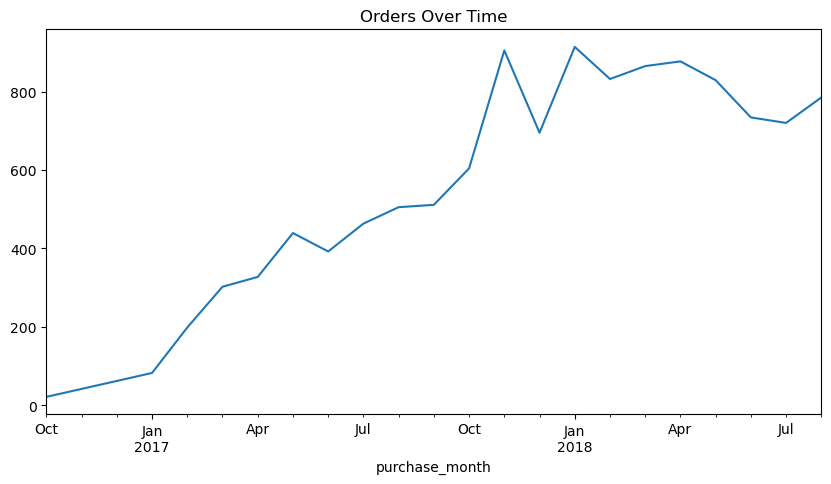

In [ ]:
monthly_orders.plot(figsize=(10,5))
plt.title("Orders Over Time")
plt.show()

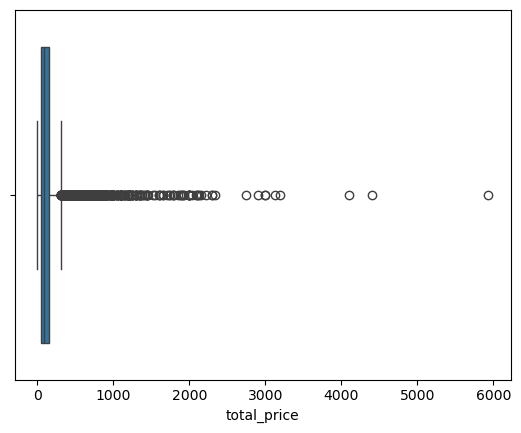

In [ ]:
sns.boxplot(
    x=order_df["total_price"]
)
plt.show()

In [ ]:
order_df.nlargest(
    10,
    "total_price"
)[["order_id", "total_price", "total_items"]]

,order_id,total_price,total_items
7360,2cc9089445046817a7539d90805e6e5a,5934.60,6
1036,d2f270487125ddc41fd134c4003ad1d7,4400.00,2
2308,68101694e5c5dc7330c91e1bbc36214f,4099.99,1
10711,cb418bb4b6115438d20b0141ed5bc9e0,3198.00,2
4605,f398a143c0fe171d965db2096cf064cf,3124.00,1
5088,d9956b0805e324db3f2a546ef216c10b,2999.99,1
5794,0af28d87520565eb3b57c9b2abe1a2cc,2999.99,1
8538,3c4a05391c2fcd152731f52de8fc4347,2899.00,1
9364,794c69999774820e22c161f6dc4fef91,2740.00,1
8470,3fde74c28a3d5d618c00f26d51baafa0,2338.08,1


## Metrics and validation

## Total Revenue


In [ ]:
total_revenue = order_items["price"].sum()
print(f"Total Revenue: R${total_revenue:,.2f}")

Total Revenue: R$1,637,360.43


## Total Freight Revenue

In [ ]:
total_freight = order_items["freight_value"].sum()
print(f"Total Freight: R${total_freight:,.2f}")

Total Freight: R$272,500.77


## Average Order Value (AOV)

In [ ]:
order_totals = (
    order_items.groupby("order_id")["price"]
    .sum()
)

aov = order_totals.mean()
print(f"Average Order Value: R${aov:.2f}")

Average Order Value: R$136.45


## Average Items per Order

In [ ]:
avg_items = (
    order_items.groupby("order_id")
    .size()
    .mean()
)

print(f"Average Items per Order: {avg_items:.2f}")

Average Items per Order: 1.15


## Order Status Distribution

In [ ]:
orders["order_status"].value_counts(normalize=True) * 100

order_status
delivered    100.0
Name: proportion, dtype: float64

## Reasonableness Check (Reconciliation)

### Orders match after aggregation

In [ ]:
order_totals = (
    order_items.groupby("order_id")
    .agg(total_price=("price", "sum"))
)

print("Unique orders in orders table:",
      orders["order_id"].nunique())

print("Unique orders in order_items table:",
      order_items["order_id"].nunique())

Unique orders in orders table: 12000
Unique orders in order_items table: 12000


## Revenue reconciliation

In [ ]:
raw_revenue = order_items["price"].sum()

agg_revenue = (
    order_items.groupby("order_id")["price"]
    .sum()
    .sum()
)

print(raw_revenue)
print(f"{agg_revenue:.2f}")
print(round(raw_revenue, 2) == round(agg_revenue, 2))

1637360.43
1637360.43
True


## Merging the DataFrames

In [ ]:
orders_enriched = orders.merge(
    order_items,
    on="order_id",
    how="left"
)

final_df = orders_enriched.merge(
    customers,
    on="customer_id",
    how="left"
)

In [ ]:
# checking the new DataFrame

final_df.shape

(13767, 18)

In [ ]:
raw_revenue = order_items["price"].sum()
final_revenue = final_df["price"].sum()

print(f"Raw Revenue: R${raw_revenue:,.2f}")
print(f"Final Revenue: R${final_revenue:,.2f}")

print("Reconciliation Passed:",
      abs(raw_revenue - final_revenue) < 0.01)

Raw Revenue: R$1,637,360.43
Final Revenue: R$1,637,360.43
Reconciliation Passed: True


In [ ]:
final_df.groupby("customer_state")[
    ["price", "freight_value"]
].mean().sort_values("price", ascending=False)

,price,freight_value
customer_state,,
AC,269.426000,53.468000
SE,207.701750,41.534750
TO,192.804524,38.647857
AL,184.042059,36.672647
MA,181.688966,34.773103
RN,158.165147,35.386471
PA,157.160388,36.706512
CE,143.181832,31.851728
PI,141.706275,36.090588


## Revenue by Customer State Visual

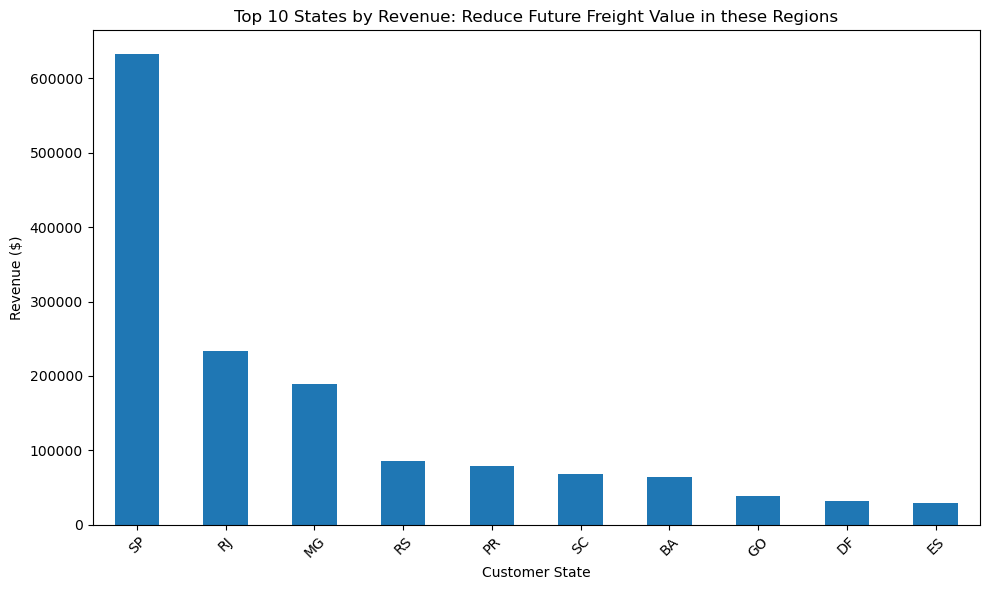

In [ ]:
state_revenue = (
    final_df
    .groupby("customer_state")["price"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10,6))

state_revenue.plot(kind="bar")

plt.title(
    "Top 10 States by Revenue: Reduce Future Freight Value in these Regions"
)
plt.xlabel("Customer State")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## States with the Lowest Freight Burden

In [ ]:
# Freight as a percentage of product revenue
state_freight_pct = (
    final_df
    .groupby("customer_state")
    .agg(
        revenue=("price", "sum"),
        freight=("freight_value", "sum")
    )
)

In [ ]:
state_freight_pct["freight_pct"] = (
    state_freight_pct["freight"] /
    state_freight_pct["revenue"]
) * 100

In [ ]:
# Top 10 most efficient states
state_freight_pct = (
    state_freight_pct
    .sort_values("freight_pct")
    .head(10)
)

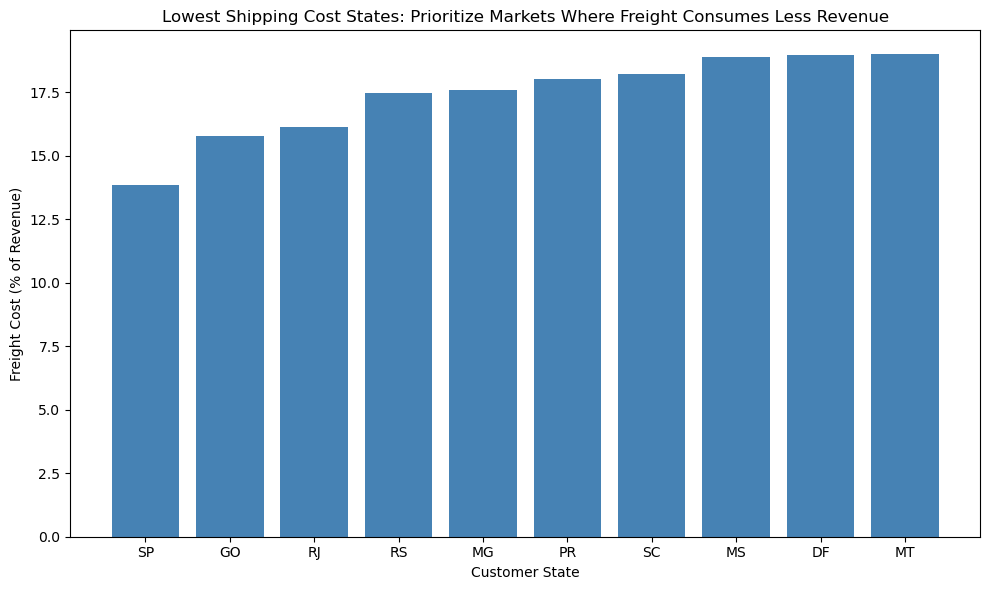

In [ ]:
plt.figure(figsize=(10, 6))

plt.bar(
    state_freight_pct.index,
    state_freight_pct["freight_pct"],
    color="steelblue"
)

plt.title(
    "Lowest Shipping Cost States: Prioritize Markets Where Freight Consumes Less Revenue"
)
plt.xlabel("Customer State")
plt.ylabel("Freight Cost (% of Revenue)")

plt.tight_layout()
plt.show()

### Business Recommendations:

1. Implement Threshold-Based Free Shipping:

    Since the vast majority of orders consist of a single item with an AOV of `R$136.45`, introduce a free or discounted shipping threshold (e.g., free shipping on orders above `R$175` or two(2) items). This incentivizes basket-building and amortizes(to gradually pay off, reduce, or spread out a cost over time) freight costs over higher cart values.
   
2.  Regional Freight Subsidies in High-Pressure States:
    
Remote northern/northeastern states (e.g., AC, RR, SE, TO) show average freight feesexceedingg`R $35R–`5`3 per order
     Parter  wthh regional 3PLs or establish regional fulfillment micro-hubs to lower delivery fees and curb cart abandonment i
    outlying  regions
    
34.   Protect Core High-Efficiency Corrido

:   
High-volume states like São Paulo (SP) benefit from low relative freig` (~$15`.00 average freight). Maintain aggrei  v
   e customer acquisition campaigns in these regions where freight friction is lowest
    
4.   SLA & Delivery Time Guaran  s    :
With delivery timaveraging ~12.32.3 days and stretchingup` o` 194 days, setting predictable delivery SLAs will roveimp
 ve customer confidence, especially for long-distance deliveries where freight costs are alrey 5

5. SLA & Delivery Time Guarantees:

    With delivery times averaging `12.3` days and stretching up to `194` days, setting predictable delivery SLAs will improve customer confidence, especially for long-distance deliveries where freight costs are already high.

### Limitations (Constraints of the Analysis)

1. 100% Delivered Order Status (Survivorship Bias):

The sample analyzed contains only delivered orders (all 12,000 orders are marked delivered). It excludes canceled, processing, or returned orders, preventing analysis of how high freight costs directly drive cart abandonment or order cancellation.

2.  Sample Size & Sampling Constraint
:
The dataset represents a subset of 12,000 orders sampled from the broader Brazilian Olist e-commerce dataset. Small sample counts in certain states (e.g., AC, RR, AP) can cause average price and freight metrics to be skewed by isolated outliers

3.   Lack of Shipping Weight and Dimension
s:
The analysis does not factor in product weight, volume, or dimensions. High freight fees in certain orders might be driven by heavy/bulky freight rather than geographic distance alone.

4.    Absence of Seller Geograp
hy:
The table includes customer location (customer_state) but omits seller state/origin. Freight cost is largely determined by origin-to-destination distance; without seller coordinates, you cannot distinguish between local intra-state deliveries and cross-country transit.

### Recommended Next Action

Investigate states with the highest freight-cost burden and evaluate opportunities to reduce shipping costs through logistics partnerships, fulfillment optimization, or regional inventory placement while continuing to invest in high-performing markets that generate strong freight-adjusted revenue.